<a href="https://colab.research.google.com/github/JaznaLaProfe/TecnicasAvanzadasML-I/blob/main/TLY1102_1_1_2_Notebook_Construir_un_Perceptron_Estudiante_Solucion.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Actividad 1.1 — Construyendo un perceptrón desde cero

## Curso: Machine Learning

En esta actividad construiremos paso a paso la idea de una neurona artificial.

La actividad tiene tres grandes etapas:

1. Calcular la combinación lineal: `Wx + b`.
2. Aplicar distintas funciones de activación.
3. Usar un perceptrón para resolver un caso simple de clasificación binaria.

Al finalizar, deberías poder explicar cómo una neurona artificial toma una decisión a partir de datos de entrada.

## Objetivos de aprendizaje

Al finalizar esta actividad serás capaz de:

- Calcular una combinación lineal del tipo $w_1*x_1 + w_2*x_2 + b$.
- Interpretar el rol de los pesos y del sesgo.
- Implementar funciones de activación simples.
- Construir un perceptrón usando NumPy.
- Aplicar el perceptrón a un caso de clasificación binaria.
- Visualizar una frontera de decisión lineal.

In [1]:
# Librerías necesarias
import numpy as np
import matplotlib.pyplot as plt

# Parte 1 — La combinación lineal: Wx + b

Antes de implementarlo en Python, recuerdar cómo una neurona artificial recibe las entradas, las multiplica por sus pesos, agrega el sesgo (bias) y produce una salida.

Donde:

- Entradas (`x`): características del problema.
- Pesos (`w`): importancia de cada característica.
- Sesgo (`b`): desplazamiento de la función.
- Salida `z` = Wx+b: combinación lineal previa a la activación.

Por lo tanto, la operación básica de una neurona artificial es:

$$z = w_1x_1 + w_2x_2 + b$$

`z` todavía no es una decisión. Es solo el resultado lineal antes de aplicar una activación.

## Actividad 1.1

Completa la siguiente función para calcular `z`.

In [2]:
def combinacion_lineal(x1, x2, w1, w2, b):
    z = None  # Reemplazar None por el cálculo correspondiente
    z = w1 * x1 + w2 * x2 + b
    return z

In [3]:
# Prueba de la función
x1 = 2
x2 = 3
w1 = 0.5
w2 = -1.0
b = 1

z = combinacion_lineal(x1, x2, w1, w2, b)
print("z =", z)

z = -1.0


### Preguntas

Responde brevemente:

1. ¿Qué ocurre con `z` si aumenta `w1`?
2. ¿Qué ocurre con `z` si `w2` es negativo?
3. ¿Qué efecto tiene el sesgo `b`?
4. ¿Puede `z` ser positivo, negativo o cero?

# Parte 2 — Vectorización con NumPy

La operación anterior también puede escribirse como producto punto:

$$z = W \cdot X + b$$

Esta forma es más compacta y permite trabajar con muchas variables de entrada.

## Actividad 1.2

Completa el cálculo usando `np.dot`.

In [4]:
X = np.array([2, 3])
W = np.array([0.5, -1.0])
b = 1

z = None  # Usar np.dot()
z = np.dot(W, X) + b
print("z =", z)

z = -1.0


In [5]:
# Ahora prueba con tres variables de entrada
X = np.array([4, 2, 1])
W = np.array([0.2, 0.8, -0.5])
b = -1

z = None  # Completar
z = np.dot(W, X) + b
print("z =", z)

z = 0.9000000000000004


### Preguntas

1. ¿Por qué es útil escribir la operación como producto punto?
2. ¿Qué representa cada elemento del vector `W`?
3. ¿Qué ocurre si cambia una entrada pero los pesos se mantienen fijos?

# Parte 3 — Funciones de activación

La combinación lineal entrega un número continuo. Para que la neurona tome una decisión, se aplica una función de activación.

En esta actividad trabajaremos con tres funciones:

1. Escalón.
2. Sigmoide.
3. ReLU.

## Actividad 1.3 — Implementar funciones de activación

Completa las tres funciones.

In [8]:
def escalon(z: int):
  """
  Implementa la función escalón.

  Si z >= 0, retorna 1.
  Si z < 0, retorna 0.

  Parameters:
  z (int): Valor de entrada.

  Returns:
  int: Valor escalado.
  """
  # Retornar 1 si z >= 0, en caso contrario retornar 0
  return np.where(z >= 0, 1, 0)

def sigmoide(z: int):
  """
  Implementa la función sigmoide.

  Parameters:
  z (int): Valor de entrada.

  Returns:
  int: Valor escalado.
  """
  # Implementar 1 / (1 + exp(-z))
  return 1 / (1 + np.exp(-z))


def relu(z: int):
  """
  Implementa la función ReLU.

  Si z >= 0, retorna z.
  Si z < 0, retorna 0.

  Parameters:
  z (int): Valor de entrada.

  Returns:
  int: Valor escalado.
  """
  # Retornar el máximo entre 0 y z
  return np.maximum(0, z)

In [9]:
# Prueba de las funciones
valores = [-3, -1, 0, 1, 3]

for z in valores:
    print("z =", z)
    print("\tescalón:", escalon(z))
    print("\tsigmoide:", sigmoide(z))
    print("\trelu:", relu(z))
    print()

z = -3
	escalón: 0
	sigmoide: 0.04742587317756678
	relu: 0

z = -1
	escalón: 0
	sigmoide: 0.2689414213699951
	relu: 0

z = 0
	escalón: 1
	sigmoide: 0.5
	relu: 0

z = 1
	escalón: 1
	sigmoide: 0.7310585786300049
	relu: 1

z = 3
	escalón: 1
	sigmoide: 0.9525741268224334
	relu: 3



# Parte 4 — Comparación visual de activaciones

Ahora graficaremos las tres funciones para comparar su comportamiento.

In [10]:
z_vals = np.linspace(-10, 10, 100)

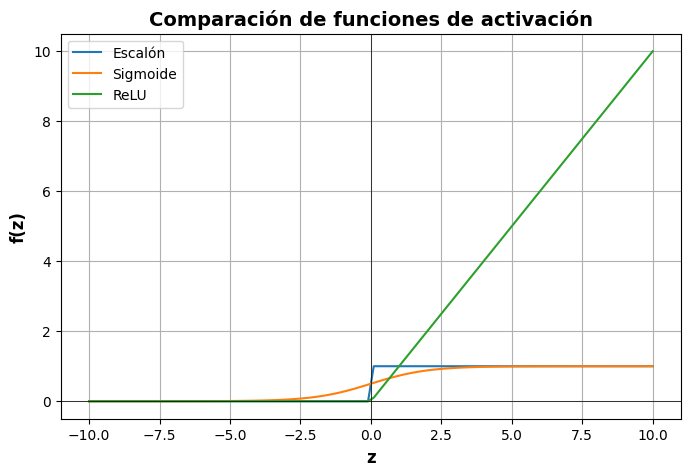

In [11]:
y_escalon = escalon(z_vals)  # Aplicar escalon a cada valor de z_vals
y_sigmoide = sigmoide(z_vals)  # Aplicar sigmoide a z_vals
y_relu = relu(z_vals)  # Aplicar relu a z_vals

plt.figure(figsize=(8, 5))
plt.plot(z_vals, y_escalon, label="Escalón")
plt.plot(z_vals, y_sigmoide, label="Sigmoide")
plt.plot(z_vals, y_relu, label="ReLU")
plt.axhline(0, color="black", linewidth=0.5)
plt.axvline(0, color="black", linewidth=0.5)
plt.xlabel("z", fontsize=12, fontweight="bold")
plt.ylabel("f(z)", fontsize=12, fontweight="bold")
plt.title("Comparación de funciones de activación", fontsize=14, fontweight="bold")
plt.legend()
plt.grid(True)
plt.show()

### Preguntas

1. ¿Cuál función sirve mejor para tomar una decisión binaria directa?
2. ¿Cuál función entrega valores entre 0 y 1?
3. ¿Cuál función permite mantener valores positivos y anular negativos?
4. ¿Por qué la función sigmoide puede interpretarse como una probabilidad?

# Parte 5 — Construcción de un perceptrón

Un perceptrón combina dos pasos:

1. Calcula una combinación lineal.
2. Aplica una función de activación.

$$z = W \cdot X + b$$

$$\hat{y} = f(z)$$

Para este primer perceptrón usaremos la función escalón.

In [12]:
def perceptron(X: np.array, W: np.array, b: np.array):
  """
  Implementa un perceptrón.

  Parameters:
  X (np.array): Vector de entrada.
  W (np.array): Vector de pesos.
  b (np.array): Sesgo.

  Returns:
  y_pred (np.array): Vector de predicciones.
  """
  z = None  # Calcular np.dot(W, X) + b
  z = np.dot(W, X) + b
  y_pred = None  # Aplicar función escalón sobre z
  y_pred = escalon(z)
  return y_pred

In [13]:
# Prueba del perceptrón
X = np.array([1, 1])
W = np.array([0.7, 0.4])
b = -0.8

prediccion = perceptron(X, W, b)
print("Predicción:", prediccion)

Predicción: 1


# Parte 6 — Caso práctico: decisión de beneficio estudiantil

Supongamos que queremos construir una neurona artificial que decida si un estudiante recibe un beneficio académico.

Usaremos dos variables:

- `x1`: nota promedio normalizada entre 0 y 1.
- `x2`: asistencia normalizada entre 0 y 1.

La salida será:

- `1`: recibe el beneficio.
- `0`: no recibe el beneficio.

In [14]:
datos = np.array([
    [0.9, 0.8],
    [0.7, 0.9],
    [0.4, 0.6],
    [0.3, 0.4],
    [0.8, 0.7],
    [0.2, 0.9],
])

etiquetas = np.array([1, 1, 0, 0, 1, 0])

print("Datos:")
print(datos)
print("Etiquetas:", etiquetas)

Datos:
[[0.9 0.8]
 [0.7 0.9]
 [0.4 0.6]
 [0.3 0.4]
 [0.8 0.7]
 [0.2 0.9]]
Etiquetas: [1 1 0 0 1 0]


## Actividad 1.4

Usa los pesos y el sesgo propuestos para clasificar cada estudiante.

In [26]:
W = np.array([0.6, 0.6])
b = -0.8

for i, X in enumerate(datos):
    pred = perceptron(X, W, b)
    print("Dato:", X, "Predicción:", pred, "Real:", etiquetas[i])

Dato: [0.9 0.8] Predicción: 1 Real: 1
Dato: [0.7 0.9] Predicción: 1 Real: 1
Dato: [0.4 0.6] Predicción: 0 Real: 0
Dato: [0.3 0.4] Predicción: 0 Real: 0
Dato: [0.8 0.7] Predicción: 1 Real: 1
Dato: [0.2 0.9] Predicción: 0 Real: 0


Análisis para la entrada 1

$0.9 x 0.6 + 0.8 x 0.6 - 0.8=0.54+0.48-0.8=0.22$

Dado que la función de activación es `escalon` entonces retornará 1 como predicción.

Análisis para la entrada 3

$0.4 x 0.6 + 0.6 x 0.6 - 0.8=0.24+0.36-0.8=-0.3$ y $escalon(-0.3) = 0$

### Preguntas

1. ¿El perceptrón clasifica correctamente todos los casos?
2. ¿Qué ocurre si el sesgo `b` se hace más negativo?
3. ¿Qué ocurre si se aumenta el peso de la nota promedio?
4. ¿Qué variable parece más importante según los pesos definidos?

# Parte 7 — Ajuste manual de pesos

Ahora debes modificar manualmente los pesos y el sesgo para mejorar las predicciones.

El objetivo es obtener la mayor cantidad posible de aciertos.

```python
W = np.array([None, None])  # Proponer pesos
b = None  # Proponer sesgo

predicciones = []

for X in datos:
    pred = perceptron(X, W, b)
    predicciones.append(pred)

predicciones = np.array(predicciones)

print("Predicciones:", predicciones)
print("Valores reales:", etiquetas)
print("Aciertos:", predicciones == etiquetas)
print("Accuracy:", np.mean(predicciones == etiquetas))
```

In [28]:
casos_a_testear = [
    {
        "W": np.array([0.4, 0.6]),
        "b": -0.2,
    },
    {
        "W": np.array([0.6, 0.4]),
        "b": -0.2,
    },
    {
        "W": np.array([0.6, 0.6]),
        "b": -0.8
    },
    {
        "W": np.array([0.6, 0.6]),
        "b": -0.8,
    },
    {
        "W": np.array([0.2, 0.6]),
        "b": -0.1
    },
    {
        "W": np.array([0.6, 0.2]),
        "b": -0.1
    }
]
for caso in casos_a_testear:
  W_caso = caso["W"]  # Proponer pesos
  b_caso = caso["b"]  # Proponer sesgo

  predicciones = []

  for X in datos:
    pred = perceptron(X, W_caso, b_caso)
    predicciones.append(pred)

  predicciones = np.array(predicciones)
  print(f"{'Caso con W'} = {caso['W']} y b = {caso['b']}")
  print("-"*40)
  print(f"{'Predicciones': <30}: {predicciones}")
  print(f"{'Valores reales': <30}: {etiquetas}")
  print(f"{'Aciertos': <30}: {predicciones == etiquetas}")
  print(f"{'Accuracy': <30}: {np.mean(predicciones == etiquetas)}")
  print("-"*40)

Caso con W = [0.4 0.6] y b = -0.2
----------------------------------------
Predicciones                  : [1 1 1 1 1 1]
Valores reales                : [1 1 0 0 1 0]
Aciertos                      : [ True  True False False  True False]
Accuracy                      : 0.5
----------------------------------------
Caso con W = [0.6 0.4] y b = -0.2
----------------------------------------
Predicciones                  : [1 1 1 1 1 1]
Valores reales                : [1 1 0 0 1 0]
Aciertos                      : [ True  True False False  True False]
Accuracy                      : 0.5
----------------------------------------
Caso con W = [0.6 0.6] y b = -0.8
----------------------------------------
Predicciones                  : [1 1 0 0 1 0]
Valores reales                : [1 1 0 0 1 0]
Aciertos                      : [ True  True  True  True  True  True]
Accuracy                      : 1.0
----------------------------------------
Caso con W = [0.6 0.6] y b = -0.8
------------------------

### Preguntas

1. ¿Qué valores finales elegiste para `W` y `b`?
2. ¿Qué accuracy obtuviste?
3. ¿Qué tuviste que modificar para mejorar el resultado?

# Parte 8 — Visualización de la frontera de decisión

El perceptrón separa el espacio de entrada mediante una frontera lineal.

Para dos variables, la frontera se obtiene cuando:

$$w_1x_1 + w_2x_2 + b = 0$$

Despejando `x2`:

$$x_2 = -\frac{w_1x_1 + b}{w_2}$$

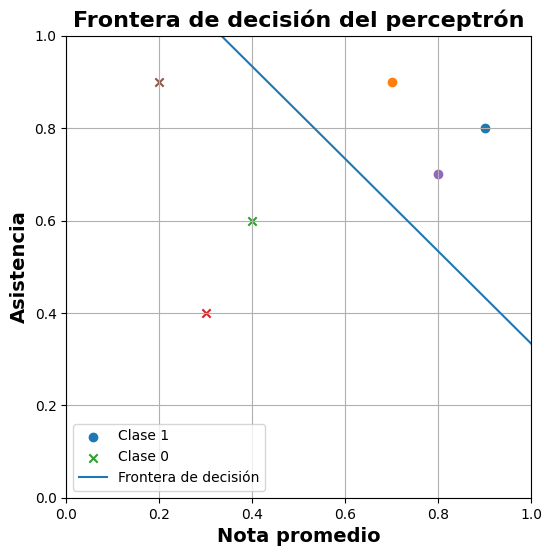

In [27]:
plt.figure(figsize=(6, 6))

for i, X in enumerate(datos):
    if etiquetas[i] == 1:
        plt.scatter(X[0], X[1], marker="o", label="Clase 1" if i == 0 else "")
    else:
        plt.scatter(X[0], X[1], marker="x", label="Clase 0" if i == 2 else "")

x_vals = np.linspace(0, 1, 100)

# TODO: completar la ecuación de la frontera de decisión
#y_vals = None
y_vals = -(W[0] * x_vals + b) / W[1]

plt.plot(x_vals, y_vals, label="Frontera de decisión")
plt.xlabel("Nota promedio", fontsize=14, fontweight="bold")
plt.ylabel("Asistencia", fontsize=14, fontweight="bold")
plt.title("Frontera de decisión del perceptrón", fontsize=16, fontweight="bold")
plt.xlim(0, 1)
plt.ylim(0, 1)
plt.grid(True)
plt.legend()
plt.show()

### Preguntas

1. ¿Qué representa la línea en el gráfico?
2. ¿Qué puntos quedan en la región clasificada como 1?
3. ¿Qué puntos quedan en la región clasificada como 0?
4. ¿Cómo cambia la frontera si modificas `w1`, `w2` o `b`?

# Cierre de la actividad

Responde las siguientes preguntas finales:

1. ¿Qué partes componen un perceptrón?
2. ¿Cuál es la diferencia entre `z` y `y_pred`?
3. ¿Qué función de activación se usó para tomar la decisión binaria?
4. ¿Qué limitación tiene este perceptrón?
5. ¿Qué tipo de problemas podría resolver?
6. ¿Qué tipo de problemas no podría resolver?

## Entrega

Debes entregar este notebook con:

- Código completado.
- Gráficos generados.
- Respuestas breves a las preguntas.
- Pesos y sesgo finales elegidos.
- Accuracy obtenido.
- Interpretación de la frontera de decisión.